# LUMA - Lokalny Rok Mistrzostwa Artystycznego 
LUNA to lokalny jarmark, któy rośnie z tyogdnia na tydzień: oraz więcej wystawców, więcej gości (miejscowi i turyści), okazjonalne promocje i sezonowość.

# Import bibliotek

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Ustawienie ziarna RNG

In [12]:
RNG_SEED = 20261018
rng = np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG: ", RNG_SEED)

Ustawiono ziarno RNG:  20261018


## Zdefiniowanie stałych

In [13]:
LUNA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
KATEGORIE = "Ceramika", "Tekstylia", "Biżuteria", "Scriptbooking", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkochole"

## Przygotowanie danych syntetycznych
"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [33]:
catalog = pd.DataFrame({
    "kategoria": KATEGORIE,
    "popyt_lok_base": (129, 100, 130, 80, 160, 150, 70, 90, 110), # średni popyt lokalny (szt./tydzn.)
    "popyt_tur_base": (60, 40, 80, 30, 90, 30, 50, 40, 80), # średni popyt turystyczny (szt./tydzn.)
    "cena_pln_base": (85, 129, 150, 230, 40, 35, 250, 215, 135), # średnia cena jednostkowa (PLN/szt.)
})

Wyliczony "typowy" przychód tygodniowy: (lokalni + turyści)* cena

In [34]:
catalog["przychod_typowy_pln"] = (catalog["popyt_lok_base"] + catalog["popyt_tur_base"] * catalog["cena_pln_base"]   )

In [16]:
catalog

,kategorie,popyt_lok_base,popyt_tur_base,cena_pln_base,przychod_typowy_pln
0,Ceramika,129,60,85,5229
1,Tekstylia,100,40,129,5260
2,Biżuteria,130,80,150,12130
3,Scriptbooking,80,30,230,6980
4,Przetwory,160,90,40,3760
5,Dekoracje,150,30,35,1200
6,Stolarka,70,50,250,12570
7,Masarstwo,90,40,215,8690
8,Alkochole,110,80,135,10910


## Przygotowanie funkcji pomocniczych do generowania danych tygodniowych 

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym i opcjonalnymi boostami (%).)

In [41]:
def losuj_popyt(catalog, rng, wariancja=0.15, boost_lok=0.0, boost_tur=0.0):
    df= catalog[["kategoria", "popyt_lok_base", "popyt_tur_base"]].copy()
    ops_l = np.clip(rng.normal(loc=1.0, scale=wariancja, size=len(df)), 0.5, 1.0)
    ops_t = np.clip(rng.normal(loc=1.0, scale=wariancja, size=len(df)), 0.5, 1.0)
    df["popyt_lok"] = (df["popyt_lok_base"] * (1 + boost_lok)) * ops_l
    df["popyt_tur"] = (df["popyt_tur_base"] * (1 + boost_tur)) * ops_t
    df["popyt_lok"] = np.maximum (df["popyt_lok"].round().astype(int), 0)
    df["popyt_tur"] = np.maximum (df["popyt_tur"].round().astype(int), 0)
    return df[["kategoria", "popyt_lok", "popyt_tur"]]
    
    


Wyliczanie przychodu lokalnegom turystycznego i łącznego

In [56]:
def policz_przychody(popyt_df, catalog):
    df = popyt_df.merge(catalog[["kategoria", "cena_pln_base"]], on="kategoria", how="left")
    df["przych_lok"] = df["popyt_lok"] + df["cena_pln_base"]
    df["przych_tur"] = df["popyt_tur"] + df["cena_pln_base"]
    df["przych_total"] = df["przych_lok"] + df["przych_tur"]
    return df[["kategoria", "przych_lok", "przych_tur", "przych_total"]]
    

Generowanie danych tygodniowych

In [54]:
def wygeneruj_tydzien(catalog, rng, wariancja=0.15, boost_lok=0.0, boost_tur=0.0):
    popyt = losuj_popyt(catalog, rng, wariancja, boost_lok, boost_tur)
    return policz_przychody(popyt, catalog)

In [ ]:
test1 = losuj_popyt(catalog, rng)
test1

## Wygenerowanie i analiza danych tygodniowych

In [58]:
t1 = wygeneruj_tydzien(catalog, rng)
t1.merge(catalog[["kategoria", "cena_pln_base"]], on="kategoria", how="left")
print("tydzien 1 - przychody per gategoria (PLN)")
display(t1)
print("Suma przychodow w tygodniu 1 (PLN): ", int(t1["przych_total"].sum()))

tydzien 1 - przychody per gategoria (PLN)


,kategoria,przych_lok,przych_tur,przych_total
0,Ceramika,214,136,350
1,Tekstylia,229,154,383
2,Biżuteria,280,230,510
3,Scriptbooking,310,260,570
4,Przetwory,191,121,312
5,Dekoracje,162,65,227
6,Stolarka,315,300,615
7,Masarstwo,274,254,528
8,Alkochole,227,212,439


Suma przychodow w tygodniu 1 (PLN):  3934


Podstawowy wykres

<Axes: >

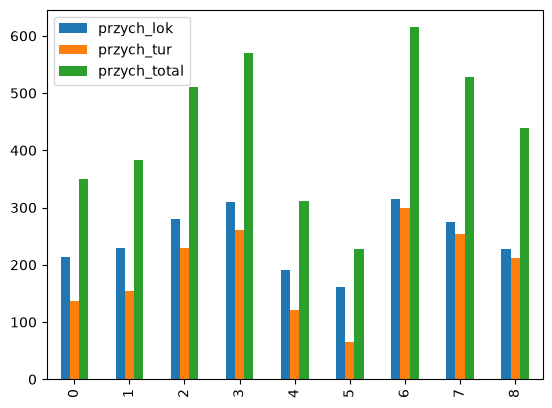

In [59]:
t1.plot.bar()

<Axes: >

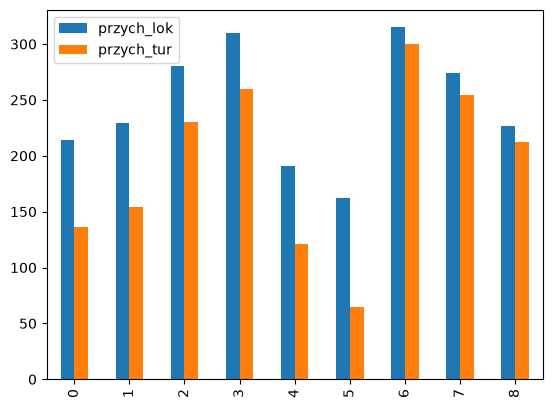

In [62]:
t1[["przych_lok", "przych_tur"]].plot.bar()